# 영상 요약과 이벤트 탐지

1946년 가정학(home economics) 교육 영상 `Arranging a Buffet Supper`를 사용해
**영상 요약**과 **타임스탬프가 포함된 이벤트 탐지(JSON)**를 실습합니다.

## 사전 준비
```bash
uv sync
ollama pull qwen3-vl:4b
```

In [1]:
import video_utils as vu

VIDEO = "data/2_cooking_steps_buffet_supper_1946.mp4"
info = vu.get_video_info(VIDEO)
info

{'fps': 29.97002997002997,
 'frame_count': 10799,
 'duration_sec': 360.32663333333335,
 'width': 640,
 'height': 480}

## 1. 영상 요약 (Video Summarization)
균등 샘플링한 프레임 전체를 한 번에 전달해 전체 흐름을 요약합니다. 영상이
6분(360초)이므로 8장만 뽑아도 45초 간격 — 큰 그림을 파악하기엔 충분합니다.

타임스탬프(초): [22.5, 67.5, 112.6, 157.6, 202.7, 247.7, 292.8, 337.8]


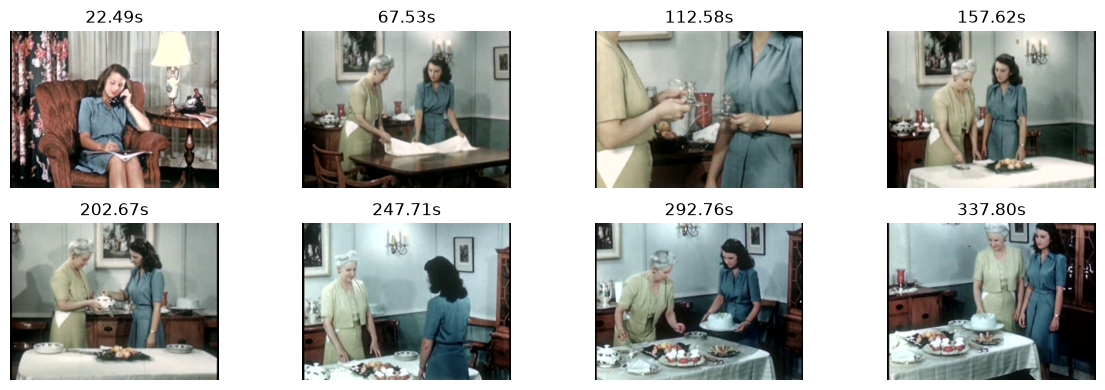

In [2]:
summary_frames = vu.extract_frames_uniform(VIDEO, n_frames=8)
print("타임스탬프(초):", [round(t, 1) for t, _ in summary_frames])
vu.show_frames(summary_frames)

In [3]:
summary = vu.ask_video(
    summary_frames,
    "아래 프레임들은 상차림(뷔페 준비) 교육 영상 전체를 균등한 간격으로 "
    "추출한 것이야. 이 영상에서 어떤 준비 과정이 시간 순서대로 진행되는지 "
    "3~4문장으로 요약해줘. 프레임에서 확인되지 않는 내용은 추측하지 마. "
    "답변은 반드시 한국어로만 작성해.",
)
print(summary)

1번 프레임은 상차림 준비의 시작 단계로 보이며, 2번 프레임에서는 두 사람이 접시와 컵을 담은 트레이를 준비하는 모습이 나타납니다. 3번 프레임에서는 주방에서 음료를 채우고 음식을 정리하는 과정이 진행되고, 4번 프레임에서는 준비된 음식과 음료가 뷔페 테이블에 배치되는 최종 단계로 이어집니다.


## 2. 이벤트 탐지 (Event Detection)
"장면/작업이 바뀌는 시점"을 찾아 구조화된 JSON으로 뽑습니다. 프롬프트에
타임스탬프가 함께 전달되므로(`ask_video`가 자동으로 붙여줌), 모델이 답변에
실제 초 단위 값을 채워 넣을 수 있습니다.

타임스탬프(초): [18.0, 54.0, 90.1, 126.1, 162.1, 198.2, 234.2, 270.2, 306.3, 342.3]


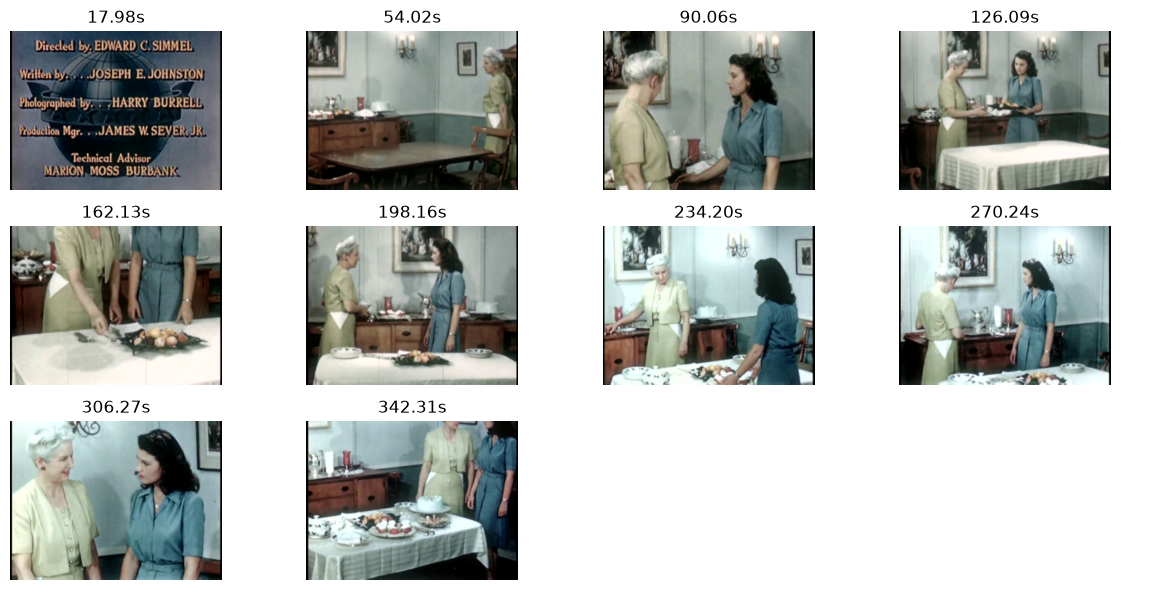

In [4]:
event_frames = vu.extract_frames_uniform(VIDEO, n_frames=10)
print("타임스탬프(초):", [round(t, 1) for t, _ in event_frames])
vu.show_frames(event_frames)

In [5]:
schema_prompt = """
아래 프레임들에서 준비 작업이 바뀌는 지점을 찾아서, 다음 JSON 스키마로만 답해.
다른 설명 문장은 출력하지 마.
{
  "events": [
    {"timestamp_sec": number, "event": "string", "description": "string"}
  ]
}
event, description 값은 모두 한국어로 작성해.
확인되지 않으면 빈 리스트를 반환해.
"""
events = vu.ask_video_json(event_frames, schema_prompt)
events

{'events': [{'timestamp_sec': 90.1,
   'event': '준비 작업 시작',
   'description': '두 여자가 테이블에 놓인 음식 재료를 준비하는 과정에서, 한 명은 테이블 위의 물건을 정리하고 다른 한 명은 재료를 확인하는 행동을 보입니다.'},
  {'timestamp_sec': 126.1,
   'event': '준비 작업 완료',
   'description': '두 여자가 테이블에 놓인 음식 재료를 모두 정리하고, 준비 작업이 완료된 상태로 이동합니다.'}]}

## 3. 결과 표로 정리
JSON 그대로도 후속 처리(DB 저장 등)가 가능하지만, 검수 목적으로 표로도
확인해봅니다.

In [6]:
for e in events.get("events", []):
    print(f"{e['timestamp_sec']:>5}s | {e['event']:<20} | {e['description']}")

 90.1s | 준비 작업 시작             | 두 여자가 테이블에 놓인 음식 재료를 준비하는 과정에서, 한 명은 테이블 위의 물건을 정리하고 다른 한 명은 재료를 확인하는 행동을 보입니다.
126.1s | 준비 작업 완료             | 두 여자가 테이블에 놓인 음식 재료를 모두 정리하고, 준비 작업이 완료된 상태로 이동합니다.


## 한계 확인
샘플링 간격(약 36초)보다 짧게 스쳐 지나가는 동작은 애초에 프레임에 담기지
않으므로 탐지될 수 없습니다. 더 정밀한 이벤트 탐지가 필요하면
`extract_frames_fixed_fps`로 더 촘촘히 샘플링하거나, 의심 구간만
`extract_frames_scene_change`로 다시 뽑아 확인하는 2단계 접근이 효과적입니다.